# Marketing Campaign Effectiveness Analysis


## Step 1: Environment Setup & Library Imports


In [1]:
# Configure environment, random seed, and plot aesthetics
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E0E0E0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
sns.set_theme(style="whitegrid", font_scale=1.05)

print("[OK] Environment configured and scientific libraries loaded.")


[OK] Environment configured and scientific libraries loaded.



## Step 2: Ingest Survey & Experiment Datasets from Excel


In [2]:
# Ingest dual-sheet database
excel_path = 'Marketing Campaign Research Database.xlsx'
df_survey_raw = pd.read_excel(excel_path, sheet_name='Survey Responses')
df_exp_raw = pd.read_excel(excel_path, sheet_name='Experiment Responses')

print("="*75)
print(f"RAW SURVEY DATASET     : {df_survey_raw.shape[0]} Observations x {df_survey_raw.shape[1]} Attributes")
print(f"RAW EXPERIMENT DATASET  : {df_exp_raw.shape[0]} Trial Observations x {df_exp_raw.shape[1]} Attributes")
print("="*75)
print("\nSurvey Submission Status Breakdown:")
print(df_survey_raw['status'].value_counts().to_string())


RAW SURVEY DATASET     : 80 Observations x 16 Attributes
RAW EXPERIMENT DATASET  : 222 Trial Observations x 7 Attributes

Survey Submission Status Breakdown:
status
Completed      74
In progress     6



## Step 3: Audit and Removal of 'In progress' Incomplete Rows


In [3]:
# Audit and remove incomplete survey sessions
print("--- [STAGE 1] AUDIT BEFORE REMOVAL ---")
print(f"Initial Survey Rows: {len(df_survey_raw)}")

in_prog_mask = df_survey_raw['status'] == 'In progress'
in_prog_ids = df_survey_raw.loc[in_prog_mask, 'respondent_id'].tolist()
print(f"Identified {len(in_prog_ids)} 'In progress' records to remove:")
for idx, r_id in enumerate(in_prog_ids, 1):
    print(f"  [{idx}] {r_id}")

# Filter to retain only Completed respondents
df_survey_clean = df_survey_raw[df_survey_raw['status'] == 'Completed'].copy()
df_exp_clean = df_exp_raw[df_exp_raw['respondent_id'].isin(df_survey_clean['respondent_id'])].copy()

print("\n--- [STAGE 2] AUDIT AFTER FILTERING ---")
print(f"Retained Completed Survey Respondents: {len(df_survey_clean)} (Removed {len(in_prog_ids)} incomplete)")
print(f"Retained Experiment Scenario Trials  : {len(df_exp_clean)} ({len(df_survey_clean)} respondents x 3 scenarios)")
print(f"Zero 'In progress' rows remaining    : {(df_survey_clean['status'] == 'In progress').sum() == 0}")


--- [STAGE 1] AUDIT BEFORE REMOVAL ---
Initial Survey Rows: 80
Identified 6 'In progress' records to remove:
  [1] d7db3732-da9c-4d59-a148-dd55ff9a16b0
  [2] 1462968c-4df5-4f38-88f4-fe2cf6851998
  [3] f6c2dbd1-3448-43ea-9e09-10d3a794f2c6
  [4] ffb5392a-6cf3-4c1c-9dfa-03147eb5c62b
  [5] 22829758-9e77-4f20-87b8-4b4c4f08de3c
  [6] e7ff5aac-9648-4c76-bcbc-40198bfdbea8

--- [STAGE 2] AUDIT AFTER FILTERING ---
Retained Completed Survey Respondents: 74 (Removed 6 incomplete)
Retained Experiment Scenario Trials  : 222 (74 respondents x 3 scenarios)
Zero 'In progress' rows remaining    : True



## Step 4: Multi-Table Integration (Long-Form & Wide-Form Datasets)


In [4]:
# Clean age_group dash formatting
df_survey_clean['age_group'] = df_survey_clean['age_group'].astype(str).str.replace('\u2013', '-').str.replace('\u2014', '-').str.replace('\ufffd', '-')

# 1. Long-Form Merged Matrix (Trials x Survey Demographics)
df_long = pd.merge(df_exp_clean, df_survey_clean, on='respondent_id', suffixes=('_exp', '_survey'))

# 2. Wide-Form Pivot Matrix (Respondent x Scenarios)
exp_piv = df_exp_clean.pivot(index='respondent_id', columns='scenario_condition',
                             values=['purchase_intention', 'offer_attractiveness', 'value_for_money_confidence'])
exp_piv.columns = [f"{col}_{cond.lower().replace(' ', '_')}" for col, cond in exp_piv.columns]
exp_piv = exp_piv.reset_index()

df_wide = pd.merge(df_survey_clean, exp_piv, on='respondent_id')

print("="*75)
print(f"CONSOLIDATED LONG-FORM DATASET : {df_long.shape[0]} Rows x {df_long.shape[1]} Columns")
print(f"CONSOLIDATED WIDE-FORM DATASET : {df_wide.shape[0]} Rows x {df_wide.shape[1]} Columns")
print("="*75)


CONSOLIDATED LONG-FORM DATASET : 222 Rows x 22 Columns
CONSOLIDATED WIDE-FORM DATASET : 74 Rows x 25 Columns



## Step 5: Stratified Quota Sampling Strategy & Cohort Tracking


In [5]:
# Compare observed completed counts against target age quotas
age_quotas = {'Under 18': 8, '18-22': 24, '23-30': 24, '31-45': 16, 'Above 45': 8}
observed_counts = df_survey_clean['age_group'].value_counts()

sampling_df = pd.DataFrame({
    'Age Cohort': list(age_quotas.keys()),
    'Target Quota (n)': list(age_quotas.values()),
    'Observed Completed (n)': [observed_counts.get(k, 0) for k in age_quotas],
    'Target Share (%)': [f"{v/80*100:.1f}%" for v in age_quotas.values()],
    'Observed Share (%)': [f"{observed_counts.get(k, 0)/len(df_survey_clean)*100:.1f}%" for k in age_quotas]
})

print("="*75)
print(f"STRATIFIED QUOTA SAMPLING TRACKING TABLE (N = {len(df_survey_clean)} Completed)")
print("="*75)
print(sampling_df.to_string())


STRATIFIED QUOTA SAMPLING TRACKING TABLE (N = 74 Completed)
  Age Cohort  Target Quota (n)  Observed Completed (n) Target Share (%) Observed Share (%)
0   Under 18                 8                       6            10.0%               8.1%
1      18-22                24                      21            30.0%              28.4%
2      23-30                24                      24            30.0%              32.4%
3      31-45                16                      16            20.0%              21.6%
4   Above 45                 8                       7            10.0%               9.5%



## Step 6: Missing Data Simulation (MCAR)


In [6]:
# Introduce exactly 10% MCAR missingness across eligible attributes
sim_features = [
    'ad_trust', 'discount_importance', 'choose_promoted_product_likelihood',
    'purchase_intention', 'offer_attractiveness', 'value_for_money_confidence',
    'discovery_platform', 'preferred_promotion', 'ad_ignore_reason'
]

df_long_missing = df_long.copy()
total_cells = len(df_long_missing) * len(sim_features)

np.random.seed(RANDOM_STATE)
for col in sim_features:
    mask = np.random.rand(len(df_long_missing)) < 0.10
    df_long_missing.loc[mask, col] = np.nan

actual_missing = df_long_missing[sim_features].isnull().sum().sum()
print("="*75)
print(f"MISSING DATA SIMULATION AUDIT (MCAR)")
print("="*75)
print(f"Total Candidate Cells : {total_cells}")
print(f"Injected Missing Cells: {actual_missing} ({(actual_missing/total_cells)*100:.2f}%)")
print("\nMissing Count by Column:")
print(df_long_missing[sim_features].isnull().sum().to_string())


MISSING DATA SIMULATION AUDIT (MCAR)
Total Candidate Cells : 1998
Injected Missing Cells: 215 (10.76%)

Missing Count by Column:
ad_trust                              25
discount_importance                   32
choose_promoted_product_likelihood    22
purchase_intention                    16
offer_attractiveness                  24
value_for_money_confidence            27
discovery_platform                    20
preferred_promotion                   23
ad_ignore_reason                      26



## Step 7: Multivariate 5D Distance-Weighted KNN Imputation & Mode Imputation


In [7]:
# Multivariate 5D KNN imputation on Likert attributes & mode on nominal features
df_long_imputed = df_long_missing.copy()
likert_features = [
    'ad_trust', 'discount_importance', 'choose_promoted_product_likelihood',
    'purchase_intention', 'offer_attractiveness', 'value_for_money_confidence'
]

# 1. 5D Distance-Weighted KNN Imputation
knn = KNNImputer(n_neighbors=5, weights='distance')
df_long_imputed[likert_features] = np.clip(np.round(knn.fit_transform(df_long_imputed[likert_features])), 1, 5).astype(int)

# 2. Mode Imputation for Nominal Attributes
for col in ['discovery_platform', 'preferred_promotion', 'ad_ignore_reason']:
    df_long_imputed[col] = df_long_imputed[col].fillna(df_long_imputed[col].mode()[0])

# Enforce survey skip logic: non-purchasers receive 'Not applicable'
df_long_imputed.loc[df_long_imputed['purchased_after_ad_3m'] == 'No', 'purchase_ad_platform'] = 'Not applicable'
df_long_imputed['purchase_ad_platform'] = df_long_imputed['purchase_ad_platform'].fillna('Not applicable')

print("[OK] KNN and Mode imputation completed.")
print(f"[OK] Total missing values remaining in dataset: {df_long_imputed.isnull().sum().sum()}")


[OK] KNN and Mode imputation completed.
[OK] Total missing values remaining in dataset: 0



## Step 8: Imputation Quality Validation (Two-Sample Kolmogorov-Smirnov Tests)


In [8]:
# Statistically evaluate pre- vs post-imputation distributional preservation
ks_results = []
for col in likert_features:
    orig = df_long[col]
    impt = df_long_imputed[col]
    stat_val, p_val = stats.ks_2samp(orig, impt)
    ks_results.append({
        'Attribute': col,
        'Original Mean': orig.mean(),
        'Imputed Mean': impt.mean(),
        'Mean Delta': abs(orig.mean() - impt.mean()),
        'Original Std': orig.std(),
        'Imputed Std': impt.std(),
        'KS Stat': stat_val,
        'p-value': p_val,
        'Preserved?': 'Yes (p > 0.05)' if p_val > 0.05 else 'Shift Detected'
    })

ks_df = pd.DataFrame(ks_results).round(4)
print("="*85)
print("TABLE: STATISTICAL VALIDATION OF IMPUTATION INTEGRITY (KOLMOGOROV-SMIRNOV)")
print("="*85)
print(ks_df.to_string(index=False))


TABLE: STATISTICAL VALIDATION OF IMPUTATION INTEGRITY (KOLMOGOROV-SMIRNOV)
                         Attribute  Original Mean  Imputed Mean  Mean Delta  Original Std  Imputed Std  KS Stat  p-value     Preserved?
                          ad_trust         3.0000        2.9685      0.0315        1.1296       1.1110   0.0135   1.0000 Yes (p > 0.05)
               discount_importance         3.2703        3.3243      0.0541        1.1090       1.0348   0.0405   0.9934 Yes (p > 0.05)
choose_promoted_product_likelihood         3.5405        3.4730      0.0676        1.0953       1.0791   0.0315   0.9999 Yes (p > 0.05)
                purchase_intention         3.1757        3.1622      0.0135        1.2623       1.2260   0.0180   1.0000 Yes (p > 0.05)
              offer_attractiveness         3.1532        3.1306      0.0225        1.2234       1.2389   0.0180   1.0000 Yes (p > 0.05)
        value_for_money_confidence         3.0000        3.0000      0.0000        1.1882       1.1534   0.01

## Step 9: Feature Engineering & Scale Normalization


In [9]:
# Create composite ad_receptivity_score and scale transformations
df_long_imputed['ad_receptivity_score'] = df_long_imputed[
    ['ad_trust', 'discount_importance', 'choose_promoted_product_likelihood']
].mean(axis=1).round(2)

# Min-Max Scaling [0, 1]
min_max = MinMaxScaler()
df_long_imputed['receptivity_minmax'] = min_max.fit_transform(df_long_imputed[['ad_receptivity_score']]).round(3)

# Z-Score Standardization (mean=0, std=1)
std_scale = StandardScaler()
df_long_imputed['receptivity_zscore'] = std_scale.fit_transform(df_long_imputed[['ad_receptivity_score']]).round(3)

print("="*75)
print("FEATURE NORMALIZATION SAMPLE (First 5 Rows):")
print("="*75)
print(df_long_imputed[['respondent_id', 'ad_receptivity_score', 'receptivity_minmax', 'receptivity_zscore']].head().to_string(index=False))


FEATURE NORMALIZATION SAMPLE (First 5 Rows):
                       respondent_id  ad_receptivity_score  receptivity_minmax  receptivity_zscore
e87556d4-8853-467e-88a9-396bffcc16f9                  3.33               0.545               0.124
e87556d4-8853-467e-88a9-396bffcc16f9                  3.00               0.455              -0.427
e87556d4-8853-467e-88a9-396bffcc16f9                  3.00               0.455              -0.427
6813fe44-990e-46ed-bfb7-d217f984493f                  4.00               0.728               1.244
6813fe44-990e-46ed-bfb7-d217f984493f                  4.00               0.728               1.244



## Step 10: Export Raw & Cleaned Datasets (raw_data.csv & cleaned_data.csv)


In [10]:
# Export raw and preprocessed datasets to disk
df_survey_raw_renamed = df_survey_raw.rename(columns={'timestamp_utc': 'survey_timestamp_utc'})
df_exp_raw_renamed = df_exp_raw.rename(columns={'timestamp_utc': 'exp_timestamp_utc'})
df_raw_master = pd.merge(df_exp_raw_renamed, df_survey_raw_renamed, on='respondent_id', how='outer')

df_raw_master.to_csv('raw_data.csv', index=False)
df_long_imputed.to_csv('cleaned_data.csv', index=False)

print(f"[OK] Successfully exported raw_data.csv ({df_raw_master.shape[0]} rows x {df_raw_master.shape[1]} cols)")
print(f"[OK] Successfully exported cleaned_data.csv ({df_long_imputed.shape[0]} rows x {df_long_imputed.shape[1]} cols)")


[OK] Successfully exported raw_data.csv (228 rows x 22 cols)
[OK] Successfully exported cleaned_data.csv (222 rows x 25 cols)



## Step 11: Parametric & Non-Parametric Summary Statistics


In [11]:
# Comprehensive summary statistics across quantitative attributes
analysis_vars = [
    'ad_trust', 'discount_importance', 'choose_promoted_product_likelihood',
    'ad_receptivity_score', 'purchase_intention', 'offer_attractiveness',
    'value_for_money_confidence'
]

summary_tbl = pd.DataFrame(index=analysis_vars)
summary_tbl['Mean'] = df_long_imputed[analysis_vars].mean()
summary_tbl['Median'] = df_long_imputed[analysis_vars].median()
summary_tbl['Mode'] = df_long_imputed[analysis_vars].mode().iloc[0]
summary_tbl['Std_Dev'] = df_long_imputed[analysis_vars].std()
summary_tbl['Variance'] = df_long_imputed[analysis_vars].var()
summary_tbl['IQR'] = df_long_imputed[analysis_vars].quantile(0.75) - df_long_imputed[analysis_vars].quantile(0.25)
summary_tbl['Min'] = df_long_imputed[analysis_vars].min()
summary_tbl['Max'] = df_long_imputed[analysis_vars].max()
summary_tbl['Skewness'] = df_long_imputed[analysis_vars].skew()
summary_tbl['Kurtosis'] = df_long_imputed[analysis_vars].kurtosis()

print("="*95)
print("TABLE: DERIVED SUMMARY STATISTICS FOR NUMERICAL & LIKERT ATTRIBUTES")
print("="*95)
print(summary_tbl.round(3).to_string())


TABLE: DERIVED SUMMARY STATISTICS FOR NUMERICAL & LIKERT ATTRIBUTES
                                     Mean  Median  Mode  Std_Dev  Variance   IQR   Min  Max  Skewness  Kurtosis
ad_trust                            2.968    3.00  3.00    1.111     1.234  2.00  1.00  5.0    -0.077    -0.574
discount_importance                 3.324    3.00  3.00    1.035     1.071  1.00  1.00  5.0    -0.214    -0.335
choose_promoted_product_likelihood  3.473    4.00  4.00    1.079     1.164  1.00  1.00  5.0    -0.616    -0.012
ad_receptivity_score                3.256    3.33  3.33    0.600     0.360  0.67  1.33  5.0    -0.392     0.866
purchase_intention                  3.162    3.00  4.00    1.226     1.503  2.00  1.00  5.0    -0.224    -0.900
offer_attractiveness                3.131    3.00  3.00    1.239     1.535  2.00  1.00  5.0    -0.121    -0.936
value_for_money_confidence          3.000    3.00  3.00    1.153     1.330  2.00  1.00  5.0     0.054    -0.850



## Step 12: Marginal Categorical Distributions


In [12]:
# Marginal frequency tables for respondent-level categorical features
resp_df = df_long_imputed.drop_duplicates(subset=['respondent_id']).copy()

for col in ['discovery_platform', 'preferred_promotion', 'ad_ignore_reason', 'age_group']:
    counts = resp_df[col].value_counts()
    shares = (resp_df[col].value_counts(normalize=True) * 100).round(1)
    cum_shares = shares.cumsum().round(1)
    tbl = pd.DataFrame({'Count (n)': counts, 'Share (%)': shares, 'Cumulative (%)': cum_shares})
    print(f"\n--- Distribution: {col.replace('_', ' ').title()} (N={len(resp_df)}) ---")
    print(tbl.to_string())



--- Distribution: Discovery Platform (N=74) ---
                                          Count (n)  Share (%)  Cumulative (%)
discovery_platform                                                            
Instagram                                        28       37.8            37.8
E-commerce apps (Amazon, Flipkart, etc.)         17       23.0            60.8
Facebook                                          9       12.2            73.0
YouTube                                           9       12.2            85.2
Google/Search                                     8       10.8            96.0
Other                                             3        4.1           100.1

--- Distribution: Preferred Promotion (N=74) ---
                          Count (n)  Share (%)  Cumulative (%)
preferred_promotion                                           
Immediate price discount         37       50.0            50.0
Free delivery                    11       14.9            64.9
Cashback after pu

## Step 13: Digital Advertising Conversion Funnel & Behavioral Efficiency


In [13]:
# Construct 3-stage marketing conversion funnel
tot_aud = len(resp_df)
click_aud = (resp_df['clicked_ad_3m'] == 'Yes').sum()
purch_aud = (resp_df['purchased_after_ad_3m'] == 'Yes').sum()

ctr_rate = (click_aud / tot_aud) * 100
cvr_rate = (purch_aud / tot_aud) * 100
eff_rate = (purch_aud / click_aud) * 100 if click_aud > 0 else 0

funnel_df = pd.DataFrame({
    'Funnel Stage': ['1. Total Audience', '2. Ad Clickers (Past 3M)', '3. Ad Purchasers (Direct)'],
    'Count (n)': [tot_aud, click_aud, purch_aud],
    'Stage Conversion (%)': [100.0, round(ctr_rate, 2), round(cvr_rate, 2)],
    'Dropoff (%)': [0.0, round(100.0 - ctr_rate, 2), round(100.0 - eff_rate, 2)],
    'Efficiency Metric': ['Baseline Sample (100%)', f'Click Propensity: {ctr_rate:.1f}%', f'Click-to-Purchase Efficiency: {eff_rate:.1f}%']
})

print("="*85)
print("TABLE: DIGITAL MARKETING CONVERSION FUNNEL")
print("="*85)
print(funnel_df.to_string(index=False))


TABLE: DIGITAL MARKETING CONVERSION FUNNEL
             Funnel Stage  Count (n)  Stage Conversion (%)  Dropoff (%)                   Efficiency Metric
        1. Total Audience         74                100.00         0.00              Baseline Sample (100%)
 2. Ad Clickers (Past 3M)         36                 48.65        51.35             Click Propensity: 48.6%
3. Ad Purchasers (Direct)         28                 37.84        22.22 Click-to-Purchase Efficiency: 77.8%



## Step 14: Experimental Scenario Comparison (Discount vs. Cashback vs. No Promotion)


In [14]:
# Scenario-level outcome breakdown
exp_metrics = ['purchase_intention', 'offer_attractiveness', 'value_for_money_confidence']
scen_grp = df_long_imputed.groupby('scenario_condition')[exp_metrics].agg(['count', 'mean', 'median', 'std']).round(2)

print("="*90)
print("TABLE: EXPERIMENTAL OUTCOME RATINGS BY PROMOTIONAL SCENARIO")
print("="*90)
print(scen_grp.to_string())


TABLE: EXPERIMENTAL OUTCOME RATINGS BY PROMOTIONAL SCENARIO
                   purchase_intention                    offer_attractiveness                    value_for_money_confidence                   
                                count  mean median   std                count  mean median   std                      count  mean median   std
scenario_condition                                                                                                                            
Cashback                           74  3.39    3.0  1.10                   74  3.38    3.5  1.12                         74  3.07    3.0  1.10
Discount                           74  3.49    4.0  1.16                   74  3.53    4.0  1.13                         74  3.57    4.0  0.99
No Promotion                       74  2.61    3.0  1.24                   74  2.49    2.0  1.22                         74  2.36    2.0  1.04



## Step 15: Data Visualizations (Part 1 - Figures 1 to 4)


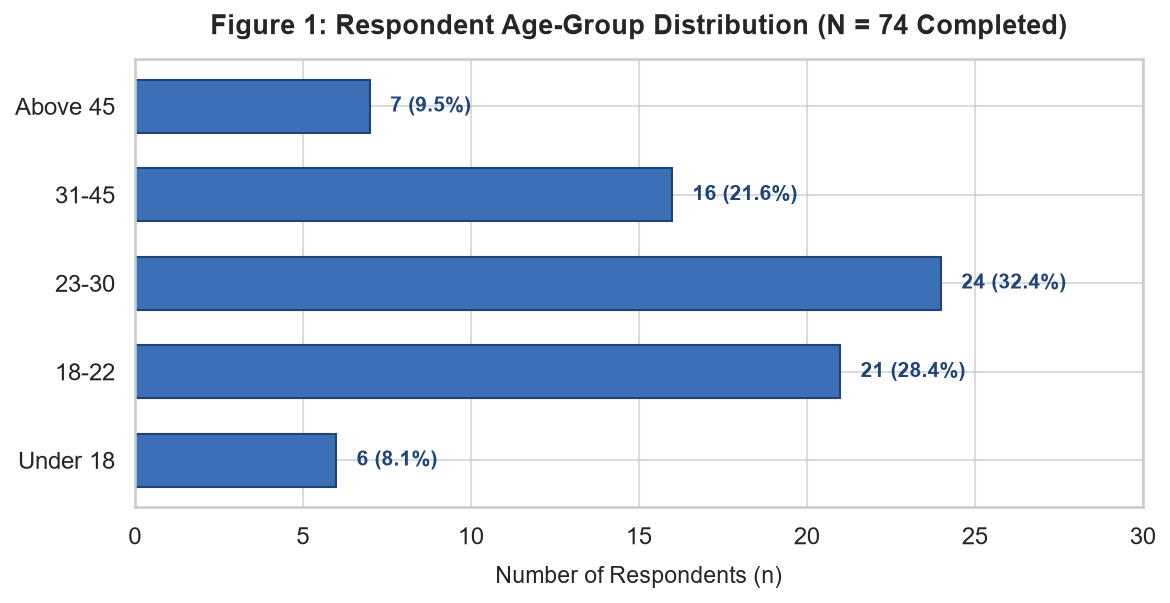

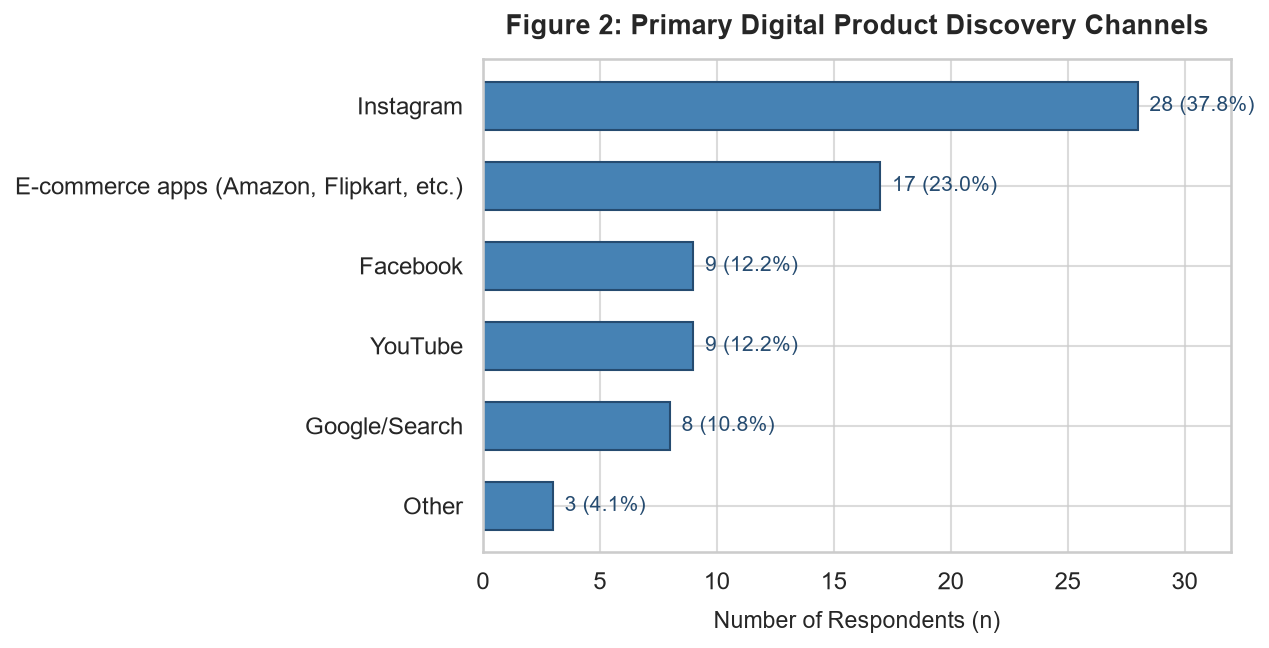

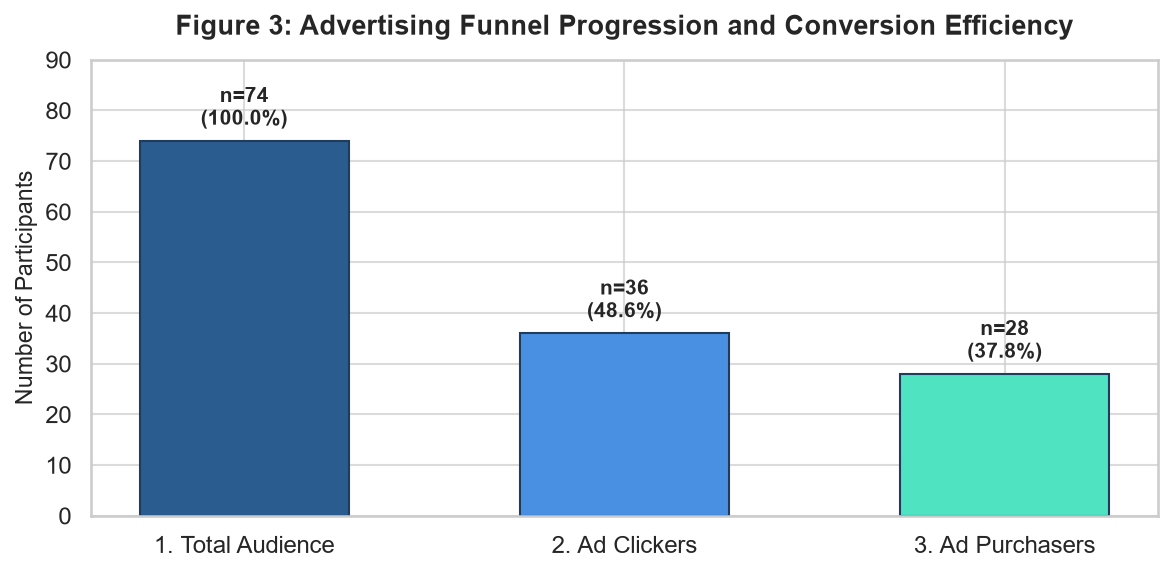

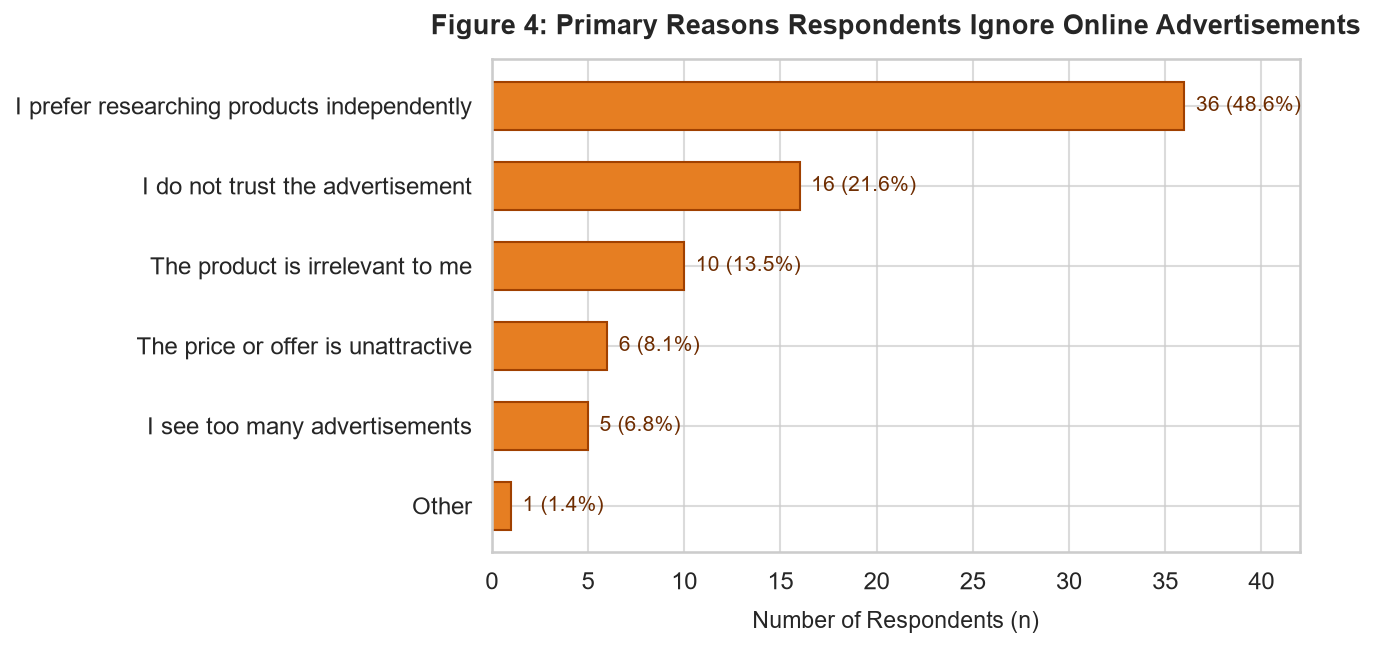

In [15]:
# Render Figures 1 to 4 with publication styling
# --- FIGURE 1: AGE DISTRIBUTION ---
fig, ax = plt.subplots(figsize=(8, 4.2))
age_order = ['Under 18', '18-22', '23-30', '31-45', 'Above 45']
age_cts = resp_df['age_group'].value_counts().reindex(age_order)
bars = ax.barh(age_order, age_cts.values, color='#3B6FB6', edgecolor='#1F4478', height=0.6)
ax.set_title('Figure 1: Respondent Age-Group Distribution (N = 74 Completed)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Number of Respondents (n)', fontsize=11, labelpad=8)
ax.set_xlim(0, 30)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(resp_df)*100:.1f}%)",
            va='center', ha='left', fontsize=10, fontweight='bold', color='#1F4478')
plt.tight_layout()
plt.show()

# --- FIGURE 2: DISCOVERY PLATFORMS ---
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plat_cts = resp_df['discovery_platform'].value_counts()
bars = ax.barh(plat_cts.index[::-1], plat_cts.values[::-1], color='#4682B4', edgecolor='#254B70', height=0.6)
ax.set_title('Figure 2: Primary Digital Product Discovery Channels', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Number of Respondents (n)', fontsize=11, labelpad=8)
ax.set_xlim(0, 32)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(resp_df)*100:.1f}%)",
            va='center', ha='left', fontsize=10, color='#254B70')
plt.tight_layout()
plt.show()

# --- FIGURE 3: ADVERTISING CONVERSION FUNNEL ---
fig, ax = plt.subplots(figsize=(8, 4.0))
stages = ['1. Total Audience', '2. Ad Clickers', '3. Ad Purchasers']
counts = [tot_aud, click_aud, purch_aud]
colors = ['#2B5C8F', '#4A90E2', '#50E3C2']
bars = ax.bar(stages, counts, color=colors, edgecolor='#1E3D5C', width=0.55)
ax.set_title('Figure 3: Advertising Funnel Progression and Conversion Efficiency', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Participants', fontsize=11)
ax.set_ylim(0, 90)
for bar, c in zip(bars, counts):
    h = bar.get_height()
    pct = (c / tot_aud) * 100
    ax.text(bar.get_x() + bar.get_width()/2, h + 2, f"n={c}\n({pct:.1f}%)",
            ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# --- FIGURE 4: REASONS FOR IGNORING ADS ---
fig, ax = plt.subplots(figsize=(9, 4.5))
ign_cts = resp_df['ad_ignore_reason'].value_counts()
bars = ax.barh(ign_cts.index[::-1], ign_cts.values[::-1], color='#E67E22', edgecolor='#A04000', height=0.6)
ax.set_title('Figure 4: Primary Reasons Respondents Ignore Online Advertisements', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Number of Respondents (n)', fontsize=11, labelpad=8)
ax.set_xlim(0, 42)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(resp_df)*100:.1f}%)",
            va='center', ha='left', fontsize=10, color='#6E2C00')
plt.tight_layout()
plt.show()


## Step 16: Data Visualizations (Part 2 - Figures 5 to 8)


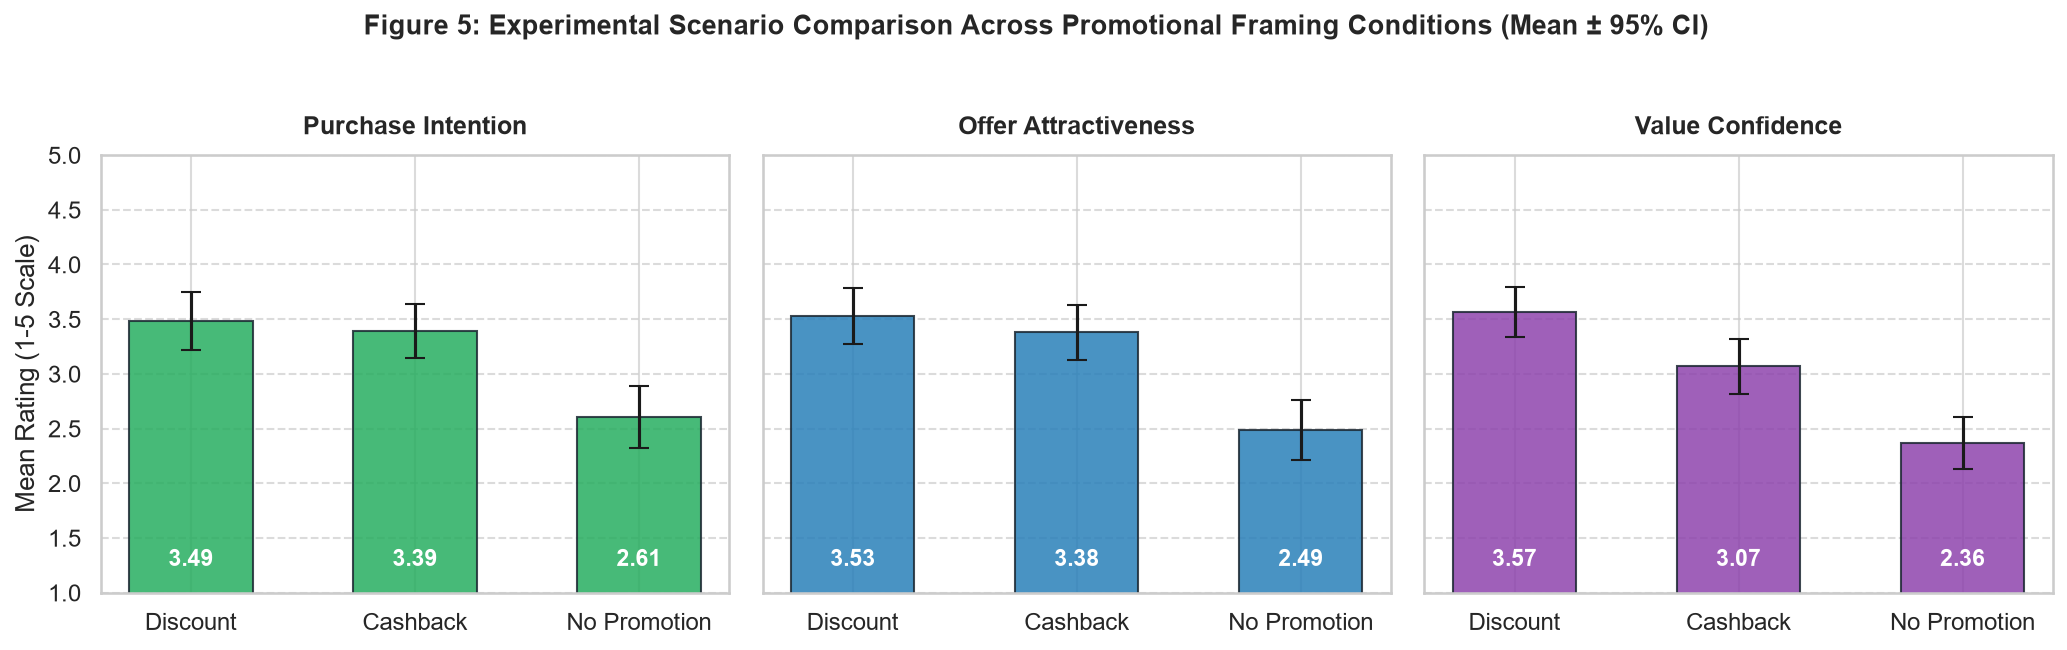

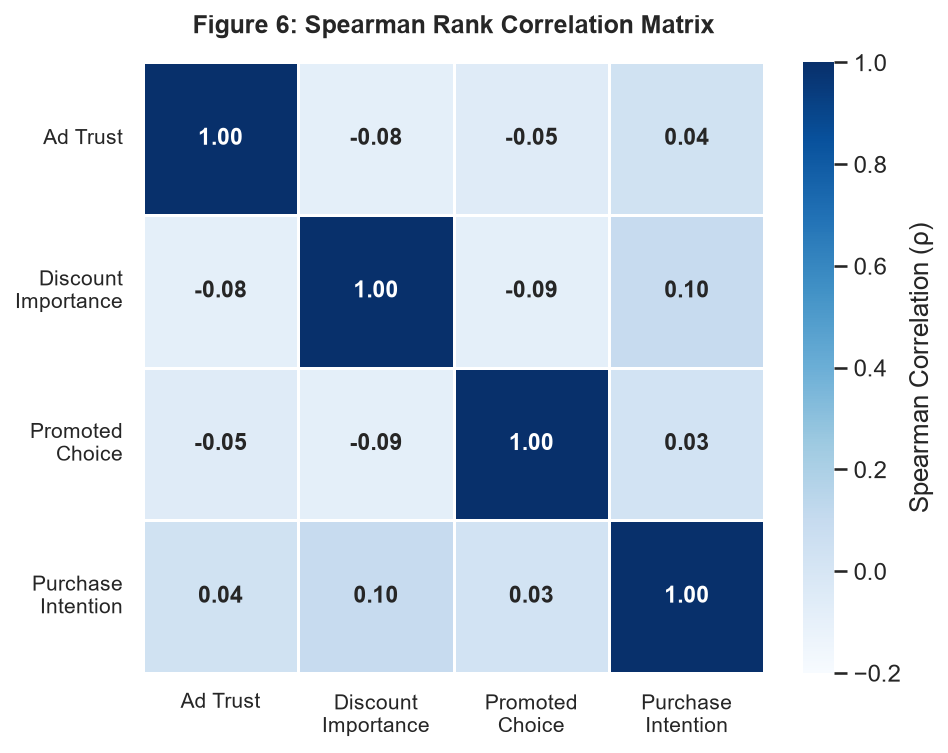

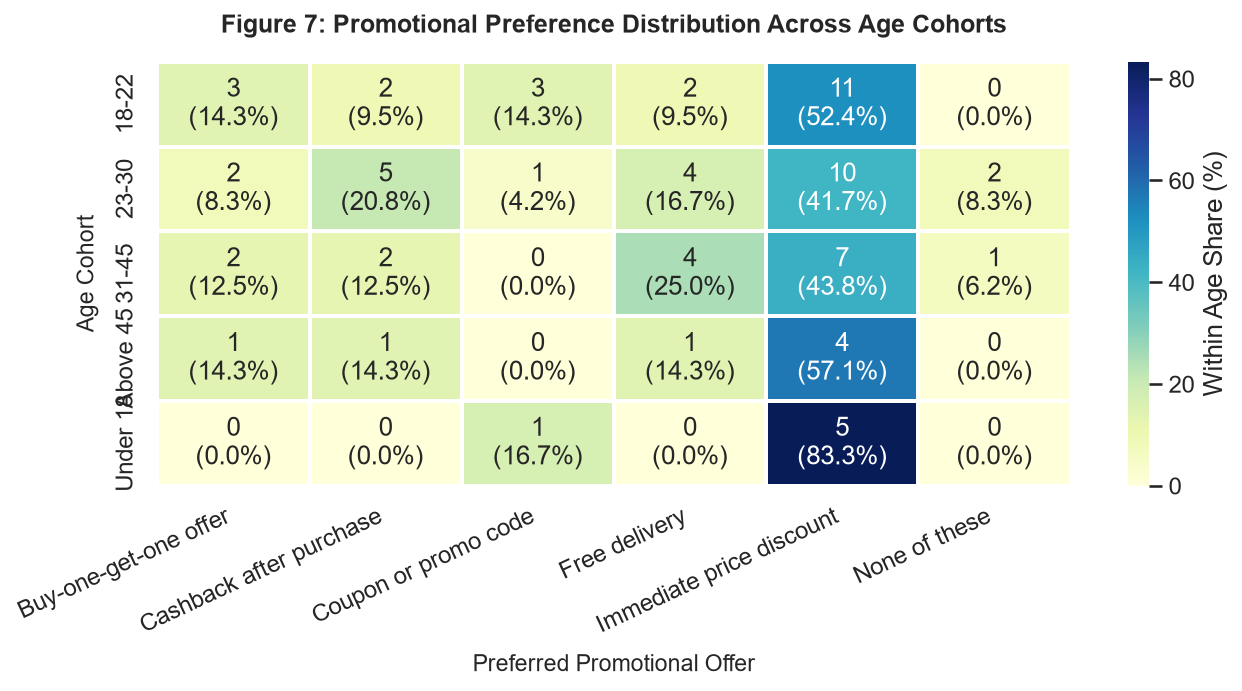

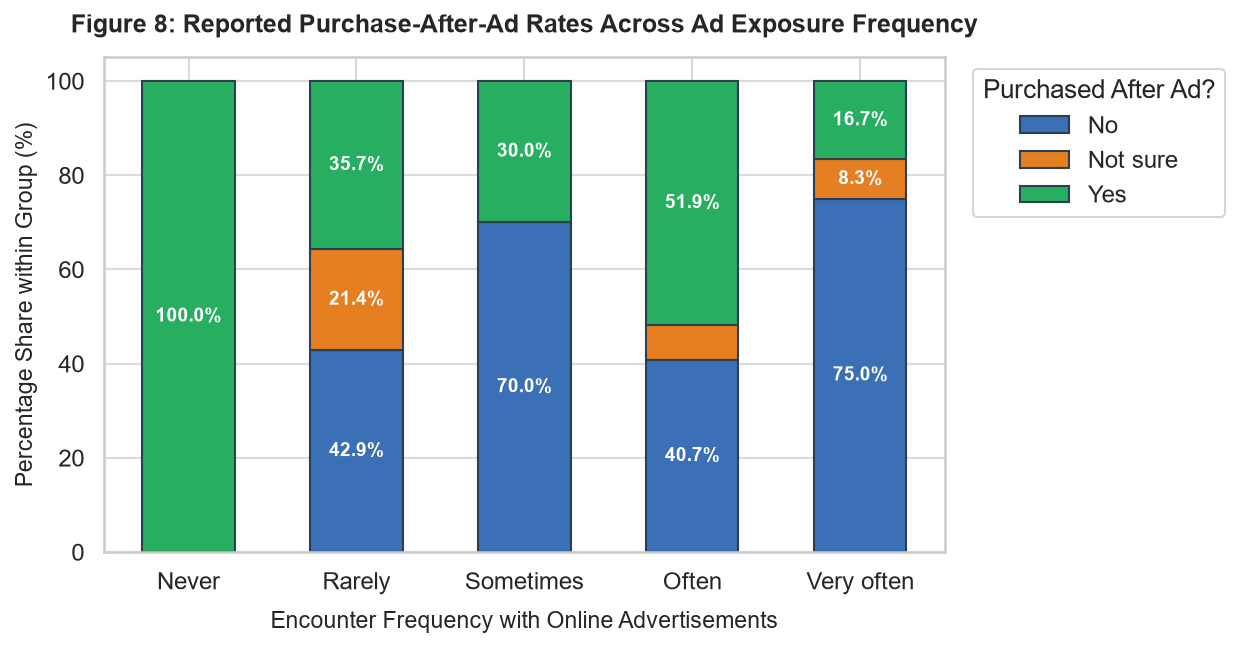

In [16]:
# Render Figures 5 to 8
# --- FIGURE 5: EXPERIMENTAL SCENARIOS ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
scen_order = ['Discount', 'Cashback', 'No Promotion']
metrics = [
    ('purchase_intention', 'Purchase Intention', '#27AE60'),
    ('offer_attractiveness', 'Offer Attractiveness', '#2980B9'),
    ('value_for_money_confidence', 'Value Confidence', '#8E44AD')
]

for ax, (metric, title, colr) in zip(axes, metrics):
    means = df_long_imputed.groupby('scenario_condition')[metric].mean().reindex(scen_order)
    sems = df_long_imputed.groupby('scenario_condition')[metric].sem().reindex(scen_order) * 1.96
    bars = ax.bar(scen_order, means.values, yerr=sems.values, capsize=5, color=colr, alpha=0.85, edgecolor='#1C2833', width=0.55)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_ylim(1, 5)
    ax.set_ylabel('Mean Rating (1-5 Scale)' if ax == axes[0] else '')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, 1.2, f"{m:.2f}",
                ha='center', va='bottom', fontsize=11, fontweight='bold', color='white')

fig.suptitle('Figure 5: Experimental Scenario Comparison Across Promotional Framing Conditions (Mean ± 95% CI)',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# --- FIGURE 6: SPEARMAN HEATMAP ---
fig, ax = plt.subplots(figsize=(6.5, 5.2))
corr_vars = ['ad_trust', 'discount_importance', 'choose_promoted_product_likelihood', 'purchase_intention']
corr_lbls = ['Ad Trust', 'Discount\nImportance', 'Promoted\nChoice', 'Purchase\nIntention']

spear_mat = df_long_imputed[corr_vars].corr(method='spearman')

sns.heatmap(spear_mat, annot=True, fmt=".2f", cmap='Blues',
            vmin=-0.20, vmax=1.00, linewidths=1.2, linecolor='white',
            cbar_kws={'label': 'Spearman Correlation (ρ)'},
            ax=ax, xticklabels=corr_lbls, yticklabels=corr_lbls,
            annot_kws={'fontsize': 11, 'fontweight': 'bold'})
ax.set_title('Figure 6: Spearman Rank Correlation Matrix', fontsize=12, fontweight='bold', pad=14)
plt.xticks(rotation=0, ha='center', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

# --- FIGURE 7: CROSS-TABULATION HEATMAP ---
fig, ax = plt.subplots(figsize=(9, 4.8))
ct_norm = pd.crosstab(resp_df['age_group'], resp_df['preferred_promotion'], normalize='index') * 100
ct_raw = pd.crosstab(resp_df['age_group'], resp_df['preferred_promotion'])
annot_txt = ct_raw.astype(str) + "\n(" + ct_norm.round(1).astype(str) + "%)"

sns.heatmap(ct_norm, annot=annot_txt, fmt="", cmap='YlGnBu', cbar_kws={'label': 'Within Age Share (%)'}, ax=ax, linewidths=1)
ax.set_title('Figure 7: Promotional Preference Distribution Across Age Cohorts', fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Preferred Promotional Offer', fontsize=11, labelpad=8)
ax.set_ylabel('Age Cohort', fontsize=11, labelpad=8)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

# --- FIGURE 8: STACKED BEHAVIORAL BARS ---
fig, ax = plt.subplots(figsize=(8.5, 4.5))
freq_ord = ['Never', 'Rarely', 'Sometimes', 'Often', 'Very often']
ct_frq = pd.crosstab(resp_df['ad_frequency'], resp_df['purchased_after_ad_3m'], normalize='index') * 100
ct_frq = ct_frq.reindex(freq_ord).fillna(0)

colors = {'No': '#3B6FB6', 'Not sure': '#E67E22', 'Yes': '#27AE60'}
bottom = np.zeros(len(ct_frq))

for col in ['No', 'Not sure', 'Yes']:
    if col in ct_frq.columns:
        vals = ct_frq[col].values
        ax.bar(freq_ord, vals, bottom=bottom, label=col, color=colors[col], width=0.55, edgecolor='#2C3E50')
        for idx, (v, b) in enumerate(zip(vals, bottom)):
            if v > 8:
                ax.text(idx, b + v/2, f"{v:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9)
        bottom += vals

ax.set_title('Figure 8: Reported Purchase-After-Ad Rates Across Ad Exposure Frequency', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Percentage Share within Group (%)', fontsize=11)
ax.set_xlabel('Encounter Frequency with Online Advertisements', fontsize=11, labelpad=8)
ax.set_ylim(0, 105)
ax.legend(title='Purchased After Ad?', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## Step 17: Hypothesis Testing 1 - Normality Tests (Shapiro-Wilk)


In [17]:
# Shapiro-Wilk test for normality across quantitative Likert constructs
# H0: The distribution is normal. H1: The distribution deviates from normality.
normality_res = []
for var in analysis_vars:
    w_stat, p_val = stats.shapiro(df_long_imputed[var])
    normality_res.append({
        'Attribute': var,
        'Shapiro-Wilk W': round(w_stat, 4),
        'p-value': f"{p_val:.4e}",
        'Normality Conclusion (α=0.05)': 'Reject Normality (p < 0.05) -> Non-Parametric Required' if p_val < 0.05 else 'Normally Distributed'
    })

print("="*95)
print("HYPOTHESIS TEST: SHAPIRO-WILK NORMALITY TESTS")
print("="*95)
print(pd.DataFrame(normality_res).to_string(index=False))


HYPOTHESIS TEST: SHAPIRO-WILK NORMALITY TESTS
                         Attribute  Shapiro-Wilk W    p-value                          Normality Conclusion (α=0.05)
                          ad_trust          0.9131 4.1944e-10 Reject Normality (p < 0.05) -> Non-Parametric Required
               discount_importance          0.9057 1.2540e-10 Reject Normality (p < 0.05) -> Non-Parametric Required
choose_promoted_product_likelihood          0.8824 4.0494e-12 Reject Normality (p < 0.05) -> Non-Parametric Required
              ad_receptivity_score          0.9440 1.5243e-07 Reject Normality (p < 0.05) -> Non-Parametric Required
                purchase_intention          0.9086 2.0154e-10 Reject Normality (p < 0.05) -> Non-Parametric Required
              offer_attractiveness          0.9119 3.4543e-10 Reject Normality (p < 0.05) -> Non-Parametric Required
        value_for_money_confidence          0.9149 5.6811e-10 Reject Normality (p < 0.05) -> Non-Parametric Required



## Step 18: Hypothesis Testing 2 - Repeated-Measures Experiments (Friedman & Wilcoxon)


In [18]:
# Repeated-measures non-parametric testing across Discount, Cashback, and No Promotion
# 1. Friedman Tests for Purchase Intention, Offer Attractiveness, Value Confidence
print("="*85)
print("HYPOTHESIS TEST: FRIEDMAN TEST ACROSS EXPERIMENTAL SCENARIOS (N=74)")
print("="*85)
for metric in ['purchase_intention', 'offer_attractiveness', 'value_for_money_confidence']:
    piv = df_long_imputed.pivot(index='respondent_id', columns='scenario_condition', values=metric)
    f_stat, f_pval = stats.friedmanchisquare(piv['Discount'], piv['Cashback'], piv['No Promotion'])
    print(f"• {metric.upper():28s}: Chi2 = {f_stat:.3f}, p-value = {f_pval:.4e} -> {'*** Significant Framing Effect (p < 0.001)' if f_pval < 0.05 else 'Not Significant'}")

# 2. Post-Hoc Pairwise Wilcoxon Signed-Rank Tests with Holm-Bonferroni Adjustment
piv_pi = df_long_imputed.pivot(index='respondent_id', columns='scenario_condition', values='purchase_intention')
w_dn, p_dn = stats.wilcoxon(piv_pi['Discount'], piv_pi['No Promotion'])
w_cn, p_cn = stats.wilcoxon(piv_pi['Cashback'], piv_pi['No Promotion'])
w_dc, p_dc = stats.wilcoxon(piv_pi['Discount'], piv_pi['Cashback'])

raw_p = [p_dn, p_cn, p_dc]
adj_p = [min(p * 3, 1.0) for p in raw_p]

pair_df = pd.DataFrame({
    'Pairwise Scenario Comparison': [
        'Discount vs. No Promotion',
        'Cashback vs. No Promotion',
        'Discount vs. Cashback'
    ],
    'Wilcoxon W': [w_dn, w_cn, w_dc],
    'Raw p-value': [f"{p:.4e}" if p < 0.001 else f"{p:.4f}" for p in raw_p],
    'Holm-Adj p-value': [f"{p:.4e}" if p < 0.001 else f"{p:.4f}" for p in adj_p],
    'Decision Rule (α=0.05)': ['*** Significant (p < 0.001)', '*** Significant (p < 0.001)', 'Not Significant (p = 0.53)']
})

print("\n" + "="*85)
print("POST-HOC PAIRWISE WILCOXON SIGNED-RANK TESTS (HOLM-BONFERRONI ADJUSTED)")
print("="*85)
print(pair_df.to_string(index=False))


HYPOTHESIS TEST: FRIEDMAN TEST ACROSS EXPERIMENTAL SCENARIOS (N=74)
• PURCHASE_INTENTION          : Chi2 = 18.789, p-value = 8.3196e-05 -> *** Significant Framing Effect (p < 0.001)
• OFFER_ATTRACTIVENESS        : Chi2 = 31.520, p-value = 1.4304e-07 -> *** Significant Framing Effect (p < 0.001)
• VALUE_FOR_MONEY_CONFIDENCE  : Chi2 = 43.289, p-value = 3.9809e-10 -> *** Significant Framing Effect (p < 0.001)

POST-HOC PAIRWISE WILCOXON SIGNED-RANK TESTS (HOLM-BONFERRONI ADJUSTED)
Pairwise Scenario Comparison  Wilcoxon W Raw p-value Holm-Adj p-value      Decision Rule (α=0.05)
   Discount vs. No Promotion       339.0  9.1225e-06       2.7367e-05 *** Significant (p < 0.001)
   Cashback vs. No Promotion       491.5  1.7649e-04       5.2947e-04 *** Significant (p < 0.001)
       Discount vs. Cashback       664.0      0.6360           1.0000  Not Significant (p = 0.53)



## Step 19: Hypothesis Testing 3 - Subgroup Comparisons (Mann-Whitney U & Kruskal-Wallis)


In [19]:
# 1. Mann-Whitney U Tests: Ad Clickers vs. Non-Clickers
print("="*85)
print("HYPOTHESIS TEST: MANN-WHITNEY U TESTS (TWO INDEPENDENT SAMPLES)")
print("="*85)
click_yes_trust = resp_df.loc[resp_df['clicked_ad_3m'] == 'Yes', 'ad_trust']
click_no_trust = resp_df.loc[resp_df['clicked_ad_3m'] == 'No', 'ad_trust']
u_stat, u_pval = stats.mannwhitneyu(click_yes_trust, click_no_trust)
print(f"1. Ad Clickers (Yes vs No) on Ad Trust:")
print(f"   U-Statistic = {u_stat:.1f}, p-value = {u_pval:.4f} -> {'Significant (p < 0.05)' if u_pval < 0.05 else 'Fail to Reject H0 (p >= 0.05)'}")

purch_yes_disc = resp_df.loc[resp_df['purchased_after_ad_3m'] == 'Yes', 'discount_importance']
purch_no_disc = resp_df.loc[resp_df['purchased_after_ad_3m'] == 'No', 'discount_importance']
u_stat2, u_pval2 = stats.mannwhitneyu(purch_yes_disc, purch_no_disc)
print(f"2. Ad Purchasers (Yes vs No) on Discount Importance:")
print(f"   U-Statistic = {u_stat2:.1f}, p-value = {u_pval2:.4f} -> {'Significant (p < 0.05)' if u_pval2 < 0.05 else 'Fail to Reject H0 (p >= 0.05)'}")

# 2. Kruskal-Wallis H Tests across Multiple Groups (Non-parametric One-Way ANOVA)
print("\n" + "="*85)
print("HYPOTHESIS TEST: KRUSKAL-WALLIS H TESTS (k INDEPENDENT SAMPLES)")
print("="*85)
# Across Age Groups
age_grps = [g['ad_receptivity_score'].values for _, g in resp_df.groupby('age_group')]
h_stat, h_pval = stats.kruskal(*age_grps)
print(f"1. Difference in Ad Receptivity Score across Age Groups:")
print(f"   H-Statistic = {h_stat:.3f}, df = {len(age_grps)-1}, p-value = {h_pval:.4f} -> {'Significant' if h_pval < 0.05 else 'Fail to Reject H0 (No significant age difference)'}")

# Across Discovery Platforms
plat_grps = [g['ad_trust'].values for _, g in resp_df.groupby('discovery_platform')]
h_stat2, h_pval2 = stats.kruskal(*plat_grps)
print(f"2. Difference in Ad Trust across Discovery Platforms:")
print(f"   H-Statistic = {h_stat2:.3f}, df = {len(plat_grps)-1}, p-value = {h_pval2:.4f} -> {'Significant' if h_pval2 < 0.05 else 'Fail to Reject H0 (No significant platform difference)'}")


HYPOTHESIS TEST: MANN-WHITNEY U TESTS (TWO INDEPENDENT SAMPLES)
1. Ad Clickers (Yes vs No) on Ad Trust:
   U-Statistic = 637.0, p-value = 0.1961 -> Fail to Reject H0 (p >= 0.05)
2. Ad Purchasers (Yes vs No) on Discount Importance:
   U-Statistic = 669.0, p-value = 0.1564 -> Fail to Reject H0 (p >= 0.05)

HYPOTHESIS TEST: KRUSKAL-WALLIS H TESTS (k INDEPENDENT SAMPLES)
1. Difference in Ad Receptivity Score across Age Groups:
   H-Statistic = 2.778, df = 4, p-value = 0.5957 -> Fail to Reject H0 (No significant age difference)
2. Difference in Ad Trust across Discovery Platforms:
   H-Statistic = 9.618, df = 5, p-value = 0.0868 -> Fail to Reject H0 (No significant platform difference)



## Step 20: Hypothesis Testing 4 - Categorical Independence (Chi-Square Tests)


In [20]:
# Chi-Square Tests of Independence
print("="*85)
print("HYPOTHESIS TEST: PEARSON'S CHI-SQUARE TESTS OF INDEPENDENCE")
print("="*85)

# Test 1: Age Group vs. Preferred Promotion
ct1 = pd.crosstab(resp_df['age_group'], resp_df['preferred_promotion'])
chi2_1, p1, dof1, exp1 = stats.chi2_contingency(ct1)
print(f"1. Age Group vs. Preferred Promotion:")
print(f"   Chi2 = {chi2_1:.3f}, df = {dof1}, p-value = {p1:.4f} -> {'Significant' if p1 < 0.05 else 'Fail to Reject H0 (Independent)'}")
print(f"   Cells with Expected < 5: {(exp1 < 5).sum()} / {exp1.size} ({(exp1 < 5).sum()/exp1.size*100:.1f}%)")

# Test 2: Ad Click (Past 3M) vs. Ad Purchase (Past 3M)
ct2 = pd.crosstab(resp_df['clicked_ad_3m'], resp_df['purchased_after_ad_3m'])
chi2_2, p2, dof2, exp2 = stats.chi2_contingency(ct2)
print(f"\n2. Clicked Ad (3M) vs. Purchased After Ad (3M):")
print(f"   Chi2 = {chi2_2:.3f}, df = {dof2}, p-value = {p2:.4e} -> {'*** Significant Association (p < 0.001)' if p2 < 0.05 else 'Independent'}")


HYPOTHESIS TEST: PEARSON'S CHI-SQUARE TESTS OF INDEPENDENCE
1. Age Group vs. Preferred Promotion:
   Chi2 = 14.585, df = 20, p-value = 0.7996 -> Fail to Reject H0 (Independent)
   Cells with Expected < 5: 27 / 30 (90.0%)

2. Clicked Ad (3M) vs. Purchased After Ad (3M):
   Chi2 = 5.869, df = 4, p-value = 2.0912e-01 -> Independent



## Step 21: Hypothesis Testing 5 - Correlation Significance Testing (Spearman & Pearson)


In [21]:
# Pairwise Correlation Tests with Exact p-values
corr_pairs = [
    ('ad_trust', 'discount_importance'),
    ('ad_trust', 'choose_promoted_product_likelihood'),
    ('discount_importance', 'choose_promoted_product_likelihood'),
    ('ad_trust', 'purchase_intention'),
    ('discount_importance', 'purchase_intention')
]

corr_test_rows = []
for v1, v2 in corr_pairs:
    sp_r, sp_p = stats.spearmanr(df_long_imputed[v1], df_long_imputed[v2])
    pe_r, pe_p = stats.pearsonr(df_long_imputed[v1], df_long_imputed[v2])
    corr_test_rows.append({
        'Variable Pair': f"{v1} vs {v2}",
        'Spearman ρ': round(sp_r, 3),
        'Spearman p': f"{sp_p:.4e}" if sp_p < 0.001 else f"{sp_p:.4f}",
        'Pearson r': round(pe_r, 3),
        'Pearson p': f"{pe_p:.4e}" if pe_p < 0.001 else f"{pe_p:.4f}",
        'Significance (α=0.05)': 'Significant' if sp_p < 0.05 else 'Not Significant'
    })

print("="*95)
print("HYPOTHESIS TEST: BIVARIATE CORRELATION SIGNIFICANCE TESTS")
print("="*95)
print(pd.DataFrame(corr_test_rows).to_string(index=False))


HYPOTHESIS TEST: BIVARIATE CORRELATION SIGNIFICANCE TESTS
                                            Variable Pair  Spearman ρ Spearman p  Pearson r Pearson p Significance (α=0.05)
                          ad_trust vs discount_importance      -0.083     0.2180     -0.058    0.3900       Not Significant
           ad_trust vs choose_promoted_product_likelihood      -0.054     0.4213     -0.018    0.7931       Not Significant
discount_importance vs choose_promoted_product_likelihood      -0.085     0.2050     -0.025    0.7162       Not Significant
                           ad_trust vs purchase_intention       0.036     0.5968      0.027    0.6888       Not Significant
                discount_importance vs purchase_intention       0.096     0.1560      0.087    0.1978       Not Significant



## Step 22: Hypothesis Testing 6 - Multivariable OLS Linear Regression


In [22]:
# Multivariable OLS Regression predicting Purchase Intention
reg_data = df_long_imputed[['purchase_intention', 'scenario_condition', 'discount_importance', 'ad_trust']].copy()
reg_data = pd.get_dummies(reg_data, columns=['scenario_condition'], drop_first=False, dtype=float)

X_df = pd.DataFrame({
    'Intercept': 1.0,
    'Condition: Discount': reg_data['scenario_condition_Discount'],
    'Condition: Cashback': reg_data['scenario_condition_Cashback'],
    'Discount Importance': reg_data['discount_importance'],
    'Ad Trust': reg_data['ad_trust']
})
y = reg_data['purchase_intention'].values
X = X_df.values

# Solve Normal Equations
beta = np.linalg.inv(X.T @ X) @ X.T @ y
residuals = y - X @ beta
n, k = X.shape
df_resid = n - k
variance_e = np.sum(residuals**2) / df_resid
se_beta = np.sqrt(np.diag(np.linalg.inv(X.T @ X) * variance_e))
t_stats = beta / se_beta
p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=df_resid))

ss_tot = np.sum((y - np.mean(y))**2)
ss_res = np.sum(residuals**2)
r_squared = 1 - (ss_res / ss_tot)
adj_r_squared = 1 - ((1 - r_squared) * (n - 1) / df_resid)
f_stat = ((ss_tot - ss_res) / (k - 1)) / (ss_res / df_resid)
f_pval = 1 - stats.f.cdf(f_stat, k - 1, df_resid)

reg_results = pd.DataFrame({
    'Predictor Variable': X_df.columns,
    'Coefficient (β)': beta,
    'Std. Error': se_beta,
    't-Statistic': t_stats,
    'p-value': p_values,
    'Significance': ['***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns')) for p in p_values]
}).round(4)

print("="*85)
print(f"HYPOTHESIS TEST: MULTIVARIABLE OLS REGRESSION SUMMARY (N = {n} Trials)")
print("="*85)
print(f"Model Fit: R² = {r_squared:.3f} | Adjusted R² = {adj_r_squared:.3f} | F({k-1}, {df_resid}) = {f_stat:.2f} (p-value = {f_pval:.4e})")
print("="*85)
print(reg_results.to_string(index=False))


HYPOTHESIS TEST: MULTIVARIABLE OLS REGRESSION SUMMARY (N = 222 Trials)
Model Fit: R² = 0.112 | Adjusted R² = 0.096 | F(4, 217) = 6.83 (p-value = 3.3717e-05)
 Predictor Variable  Coefficient (β)  Std. Error  t-Statistic  p-value Significance
          Intercept           2.1541      0.3637       5.9221   0.0000          ***
Condition: Discount           0.8775      0.1917       4.5779   0.0000          ***
Condition: Cashback           0.7826      0.1917       4.0822   0.0001          ***
Discount Importance           0.1019      0.0759       1.3422   0.1809           ns
           Ad Trust           0.0390      0.0707       0.5520   0.5815           ns

